# Standard Vector RAG vs. GraphRAG 완벽 비교 (로컬 LLM & 그래프 시각화)

본 노트북은 **Standard Vector RAG(벡터 유사도 기반 검색)**의 구조적 한계를 직접 확인하고, 이를 **GraphRAG(지식 그래프 기반 멀티홉 추론)**로 해결하는 과정을 단계별로 실습하기 위해 제작된 강좌용 예제입니다.

---

### 학습 목표
1. **Standard Vector RAG의 한계 이해**: 질문에 등장하는 단어/의미와의 단순 코사인 유사도(Top-$K$)만으로는 **징검다리(Multi-Hop) 문단**을 검색하지 못해 추론에 실패하는 현상을 확인합니다.
2. **로컬 LLM (LM Studio / Ollama 등) 연동**: 외부 유료 API Key 없이 OpenAI 호환 로컬 엔드포인트(`http://localhost:1234/v1`)와 `Pydantic` 구조화 출력(`with_structured_output`)을 결합하여 지식 그래프를 구축합니다.
3. **GraphRAG 파이프라인 구현**: 텍스트에서 추출한 엔티티(Node)와 관계(Edge)를 `NetworkX` 그래프로 변환하고, 최단 경로 탐색(Shortest Path)을 통해 멀티홉 컨텍스트를 구성합니다.
4. **지식 그래프 시각화**: 전체 인간관계 네트워크와 질문의 정답 경로(3-Hop Path)를 **정적 그래프(Matplotlib)** 및 **인터랙티브 그래프(PyVis)**로 시각화합니다.

---

### 실행 환경 안내 (로컬 LLM 연동 방법)
* **방법 A (로컬 런타임 연결 - 권장)**: PC에서 **LM Studio**를 실행하고 Local Server(`http://localhost:1234/v1`)를 켠 뒤, Colab 우측 상단 `연결` 버튼 옆 화살표 $\rightarrow$ `로컬 런타임에 연결`을 사용하거나 Jupyter/VSCode에서 바로 실행합니다.
* **방법 B (Colab 클라우드 런타임 + 터널링)**: 로컬 PC의 LM Studio 포트를 `ngrok` 또는 `cloudflared`로 포워딩하여 생성된 URL을 `BASE_URL`에 입력합니다.

## Step 1. 필수 라이브러리 및 한글 폰트 설치

실습에 필요한 LangChain, FAISS 벡터 DB, 한국어 임베딩(`BAAI/bge-m3`), 그래프 분석(`networkx`) 및 시각화(`matplotlib`, `pyvis`) 패키지와 그래프 출력용 나눔고딕 한글 폰트를 설치합니다.

In [1]:
# 1. 필수 파이썬 패키지 설치
!pip install -q langchain langchain-core langchain-community langchain-openai langchain-huggingface \
                faiss-cpu sentence-transformers networkx matplotlib pyvis pydantic

# 2. 시각화를 위한 리눅스(Colab) 한글 폰트(나눔고딕) 설치
!apt-get -qq -y install fonts-nanum > /dev/null

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# 설치된 나눔바른고딕 폰트를 Matplotlib에 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    plt.rc('font', family='NanumBarunGothic')
    plt.rcParams['axes.unicode_minus'] = False
    print("✅ 한글 폰트(NanumBarunGothic) 설정이 완료되었습니다.")
else:
    print("⚠️ 나눔 폰트를 찾을 수 없습니다. 로컬 OS 기본 폰트를 확인해주세요.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 55.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests

## Step 2. 로컬 LLM (LM Studio) 클라이언트 설정 및 데이터셋 준비

### 데이터셋 설계 포인트 (왜 Standard RAG는 실패하는가?)
우리가 해결할 질문은 **"김민수에서 조현우까지의 연결 경로는 무엇인가요?"** 입니다.
* **Chunk 1**: `김민수`와 주변 인물(`박지영`, `이준호`, `김소영`)이 등장합니다.
* **Chunk 2**: 대학원/봉사 동아리 등 주변부 지인 관계(`임서연`, `정수진`, `최영희`, `한지훈`)가 등장합니다.
* **Chunk 3 (핵심 징검다리)**: `이준호`와 `박지영`이 각각 동호회에서 `강동훈`과 친분을 맺는 내용입니다. **(주의: 이 문단에는 '김민수'와 '조현우'라는 단어가 단 한 번도 등장하지 않습니다!)**
* **Chunk 4**: `조현우`가 마라톤 동호회에서 `강동훈`을 만나는 내용입니다.

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.documents import Document

# =====================================================================
# [로컬 LLM 설정] LM Studio의 OpenAI 호환 서버 주소 및 모델명 설정
# =====================================================================
LOCAL_BASE_URL = "https://integrate.api.nvidia.com/v1"
LOCAL_API_KEY = "your_api_key"
LOCAL_MODEL_NAME = "openai/gpt-oss-20b"

# ChatOpenAI 클래스를 사용하여 로컬 LLM 인스턴스 초기화
# 일관된 사실 추론과 그래프 추출을 위해 temperature=0으로 설정합니다.
llm = ChatOpenAI(
    base_url=LOCAL_BASE_URL,
    api_key=LOCAL_API_KEY,
    model=LOCAL_MODEL_NAME,
    temperature=0
)

# =====================================================================
# [실습 데이터셋] 4개의 독립된 문단(Chunk)과 타겟 질문 정의
# =====================================================================
raw_paragraphs = [
    # Chunk 1: 김민수의 1촌 관계 (박지영, 이준호, 김소영)
    "김민수는 대학교 컴퓨터공학과 동기인 박지영과 오랜 친구 관계를 유지하고 있습니다. 현재 IT 회사에 재직 중인 김민수는 같은 회사 동료인 이준호와 함께 핵심 프로젝트를 진행하며 긴밀한 업무 파트너십을 맺고 있습니다. 가족 관계로는 김소영이 형제이며, 주말마다 함께 테니스 동호회에 나가 테니스를 즐깁니다.",

    # Chunk 2: 확장 지인 관계 (정답 경로와 무관한 Distractor 포함)
    "조금 더 자세한 지인 관계망을 살펴보면, 김소영은 대학교 봉사 동아리를 통해 임서연과 친해져 카페에서 자주 모입니다. 박지영은 대학원에 진학해 후배 정수진과 교류하고 있으며, 사내의 다른 동료인 최영희와도 가깝게 지냅니다. 선후배 관계로는 한지훈과 정수진이 있습니다.",

    # Chunk 3: 핵심 징검다리 문단 ('김민수', '조현우'가 전혀 등장하지 않음!)
    "사내외 동호회 활동을 통한 교류도 무척 활발합니다. 회사 내 축구 동호회에서 핵심 멤버로 뛰고 있는 이준호는 부서가 다른 강동훈과 매주 연습을 하며 매우 막역한 사이가 되었습니다. 박지영 역시 사외 등산 동호회에서 강동훈을 알게 되어 종종 산행을 함께 하며 친분을 쌓았습니다.",

    # Chunk 4: 조현우의 1촌 관계 (강동훈)
    "최근 IT 스타트업을 창업한 조현우는 업무 스트레스를 풀기 위해 마라톤 동호회에 가입했습니다. 조현우는 이 마라톤 동호회에서 강동훈을 만나 깊은 친분을 맺었으며, 주말마다 함께 러닝을 하며 스타트업 운영 및 IT 업계 동향에 대한 깊은 고민을 나눕니다."
]

# LangChain Document 객체 리스트로 변환 (메타데이터에 chunk_id 부여)
docs = [
    Document(page_content=text, metadata={"chunk_id": idx + 1})
    for idx, text in enumerate(raw_paragraphs)
]

# 사용자 질문
query = "김민수에서 조현우까지의 연결 경로는 무엇인가요?"

print(f"✅ 총 {len(docs)}개의 문서 청크(Chunk)가 준비되었습니다.")
for d in docs:
    print(f"  - [Chunk {d.metadata['chunk_id']}] {d.page_content[:45]}...")

✅ 총 4개의 문서 청크(Chunk)가 준비되었습니다.
  - [Chunk 1] 김민수는 대학교 컴퓨터공학과 동기인 박지영과 오랜 친구 관계를 유지하고 있습니다....
  - [Chunk 2] 조금 더 자세한 지인 관계망을 살펴보면, 김소영은 대학교 봉사 동아리를 통해 임서...
  - [Chunk 3] 사내외 동호회 활동을 통한 교류도 무척 활발합니다. 회사 내 축구 동호회에서 핵심...
  - [Chunk 4] 최근 IT 스타트업을 창업한 조현우는 업무 스트레스를 풀기 위해 마라톤 동호회에 ...


## Step 3. Standard Vector RAG 구현 및 한계 확인 (실패 시나리오)

Standard Vector RAG는 질문을 임베딩 벡터로 변환한 뒤, 각 청크와의 코사인 유사도를 계산하여 상위 $K$개(`k=2`)의 문단을 가져옵니다.
* 질문에 **'김민수'**와 **'조현우'**가 포함되어 있으므로, 벡터 검색기는 **Chunk 1(김민수 등장)**과 **Chunk 4(조현우 등장)**만 가져옵니다.
* 정작 두 세계를 연결해 주는 **Chunk 3(박지영/이준호 $\leftrightarrow$ 강동훈)**은 유사도 순위에서 밀려 누락되므로, LLM은 연결 고리를 찾지 못합니다.

In [3]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 1. 한국어 문맥 파악 능력이 우수한 로컬 임베딩 모델(BAAI/bge-m3) 로드
print("⏳ 로컬 임베딩 모델(BAAI/bge-m3)을 로드하고 벡터 인덱스를 생성합니다...")
embeddings = HuggingFaceEmbeddings(model_name="BAAI/bge-m3")

# 2. FAISS 벡터 데이터베이스에 4개의 청크 인덱싱
vectorstore = FAISS.from_documents(docs, embeddings)

# 3. 유사도 검색 수행 (Top-K = 2 설정)
# 현업에서는 컨텍스트 윈도우 및 노이즈 제어를 위해 Top-K로 문서를 제한합니다.
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})
retrieved_docs = retriever.invoke(query)

print("\n🔍 [Standard Vector RAG가 검색한 Top-2 청크]")
print("=" * 70)
for d in retrieved_docs:
    print(f"📌 [Chunk {d.metadata['chunk_id']}] {d.page_content}")
print("=" * 70)
print("👉 핵심 포인트: 징검다리 정보가 담긴 [Chunk 3]이 검색 결과에서 완전히 누락되었습니다!\n")

# 4. 검색된 청크만을 바탕으로 로컬 LLM에게 답변 생성 요청
standard_rag_prompt = ChatPromptTemplate.from_template("""
당신은 제공된 문맥(Context)만을 바탕으로 사실에 입각해 답변하는 AI 어시스턴트입니다.
문맥에 명시되지 않은 인물 관계는 절대 추측하거나 지어내지 마세요.

[Context]
{context}

[Question]
{question}

[Answer]
""")

# 검색된 문단을 하나의 텍스트로 병합
formatted_context = "\n\n".join([
    f"[문단 {d.metadata['chunk_id']}] {d.page_content}" for d in retrieved_docs
])

standard_chain = standard_rag_prompt | llm | StrOutputParser()

print("🤖 [Standard Vector RAG 최종 답변 생성 중...]")
try:
    standard_answer = standard_chain.invoke({
        "context": formatted_context,
        "question": query
    })
    print("\n❌ [Standard Vector RAG 답변 결과]:")
    print(standard_answer)
except Exception as e:
    print(f"\n⚠️ 로컬 LLM 서버 연결을 확인해주세요 ({LOCAL_BASE_URL}): {e}")

⏳ 로컬 임베딩 모델(BAAI/bge-m3)을 로드하고 벡터 인덱스를 생성합니다...


/tmp/ipykernel_13355/1932269392.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]


🔍 [Standard Vector RAG가 검색한 Top-2 청크]
📌 [Chunk 1] 김민수는 대학교 컴퓨터공학과 동기인 박지영과 오랜 친구 관계를 유지하고 있습니다. 현재 IT 회사에 재직 중인 김민수는 같은 회사 동료인 이준호와 함께 핵심 프로젝트를 진행하며 긴밀한 업무 파트너십을 맺고 있습니다. 가족 관계로는 김소영이 형제이며, 주말마다 함께 테니스 동호회에 나가 테니스를 즐깁니다.
📌 [Chunk 4] 최근 IT 스타트업을 창업한 조현우는 업무 스트레스를 풀기 위해 마라톤 동호회에 가입했습니다. 조현우는 이 마라톤 동호회에서 강동훈을 만나 깊은 친분을 맺었으며, 주말마다 함께 러닝을 하며 스타트업 운영 및 IT 업계 동향에 대한 깊은 고민을 나눕니다.
👉 핵심 포인트: 징검다리 정보가 담긴 [Chunk 3]이 검색 결과에서 완전히 누락되었습니다!

🤖 [Standard Vector RAG 최종 답변 생성 중...]

❌ [Standard Vector RAG 답변 결과]:
김민수와 조현우 사이에는 주어진 문맥에서 직접적이거나 간접적인 인물 관계가 나타나지 않습니다. 따라서 두 인물 사이의 연결 경로는 존재하지 않습니다.


## Step 4. GraphRAG 구현 (1): 지식 그래프(Knowledge Graph) 구축

이제 **GraphRAG**를 구현합니다. 첫 번째 단계는 비정형 텍스트(4개의 문단)에서 **엔티티(인물)**와 **관계(Edge)**를 구조화된 형태로 추출하여 그래프 데이터베이스(`NetworkX`)에 저장하는 것입니다.

* **로컬 LLM + Pydantic 구조화 출력**: `llm.with_structured_output(KnowledgeGraph)`를 사용하여 LLM이 항상 정해진 JSON 스키마(`source`, `target`, `relation`)로 응답하도록 강제합니다.
* **폴백(Fallback) 지원**: 만약 수강생의 로컬 환경에서 아직 LM Studio를 실행하지 않았거나 소형 모델의 JSON 파싱 오류가 발생하더라도, 강좌 실습이 중단되지 않도록 정밀 추출된 그래프 데이터로 자동 전환되는 안전장치가 포함되어 있습니다.

In [4]:
import networkx as nx
from pydantic import BaseModel, Field
from typing import List

# 1. Pydantic을 활용한 지식 그래프 추출 스키마 정의
class Relationship(BaseModel):
    source: str = Field(description="출발 인물 이름 (예: 김민수)")
    target: str = Field(description="도착 인물 이름 (예: 박지영)")
    relation: str = Field(description="두 인물 간의 구체적인 관계 요약 (예: 대학 동기/친구, 사내 축구 동호회 등)")

class KnowledgeGraph(BaseModel):
    edges: List[Relationship] = Field(description="텍스트에서 추출된 모든 인물 간의 관계 리스트")

# 2. 지식 그래프 추출용 프롬프트 작성
kg_extraction_prompt = ChatPromptTemplate.from_template("""
주어진 텍스트를 읽고 등장하는 모든 인물(Person) 간의 관계를 빠짐없이 추출하세요.
- 인물 이름은 텍스트에 나온 그대로 정확히 기입하세요.
- relation에는 학교, 회사, 가족, 동호회(테니스, 축구, 등산, 마라톤 등) 맥락을 간결하고 명확하게 포함하세요.

[텍스트]
{text}
""")

# 3. NetworkX 무방향 그래프(Undirected Graph) 객체 생성
# 인간관계(친구, 동료, 동호회 멤버)는 양방향 소통이 가능하므로 무방향 그래프(nx.Graph)로 모델링합니다.
G = nx.Graph()

print("🕸️ [GraphRAG: 문단별 엔티티 및 관계 추출 시작]")
print("=" * 70)

try:
    # 로컬 LLM의 Structured Output 기능을 사용해 실시간으로 그래프 추출
    kg_extractor = kg_extraction_prompt | llm.with_structured_output(KnowledgeGraph)

    for doc in docs:
        chunk_id = doc.metadata["chunk_id"]
        extracted_kg = kg_extractor.invoke({"text": doc.page_content})

        for edge in extracted_kg.edges:
            G.add_edge(
                edge.source.strip(),
                edge.target.strip(),
                relation=edge.relation.strip(),
                chunk_id=chunk_id
            )
            print(f"  ✔ [Chunk {chunk_id}] ({edge.source}) ---[{edge.relation}]---> ({edge.target})")

except Exception as e:
    # 로컬 LLM 미실행 또는 Structured Output 미지원 모델을 위한 강좌용 안전장치(Fallback)
    print(f"ℹ️ 로컬 LLM 실시간 추출 대신 사전 검증된 정밀 추출 결과를 로드합니다. (사유: {e})")
    fallback_edges = [
        # Chunk 1
        ("김민수", "박지영", "컴퓨터공학과 동기 및 오랜 친구", 1),
        ("김민수", "이준호", "같은 IT 회사 동료 및 핵심 프로젝트 파트너", 1),
        ("김민수", "김소영", "형제 관계 및 주말 테니스 동호회", 1),
        # Chunk 2
        ("김소영", "임서연", "대학교 봉사 동아리 친구", 2),
        ("박지영", "정수진", "대학원 선후배 관계", 2),
        ("박지영", "최영희", "사내 친한 동료", 2),
        ("한지훈", "정수진", "선후배 관계", 2),
        # Chunk 3 (핵심 징검다리)
        ("이준호", "강동훈", "사내 축구 동호회 핵심 멤버", 3),
        ("박지영", "강동훈", "사외 등산 동호회 지인", 3),
        # Chunk 4
        ("조현우", "강동훈", "마라톤 동호회 러닝 파트너", 4),
    ]
    for u, v, rel, cid in fallback_edges:
        G.add_edge(u, v, relation=rel, chunk_id=cid)
        print(f"  ✔ [Chunk {cid}] ({u}) ---[{rel}]---> ({v})")

print("=" * 70)
print(f"✅ 지식 그래프 구축 완료! 총 노드(인물) 수: {G.number_of_nodes()}명, 총 엣지(관계) 수: {G.number_of_edges()}개")

🕸️ [GraphRAG: 문단별 엔티티 및 관계 추출 시작]
  ✔ [Chunk 1] (김민수) ---[대학교 컴퓨터공학과 동기, 오랜 친구]---> (박지영)
  ✔ [Chunk 1] (김민수) ---[IT 회사 동료, 핵심 프로젝트 파트너]---> (이준호)
  ✔ [Chunk 1] (김민수) ---[형제, 주말 테니스 동호회 동료]---> (김소영)
  ✔ [Chunk 2] (김소영) ---[대학교 봉사 동아리 친구 (카페에서 자주 모임)]---> (임서연)
  ✔ [Chunk 2] (박지영) ---[대학원 후배 (교류)]---> (정수진)
  ✔ [Chunk 2] (박지영) ---[사내 동료 (가깝게 지냄)]---> (최영희)
  ✔ [Chunk 2] (정수진) ---[선후배 관계 (학교)]---> (한지훈)
  ✔ [Chunk 3] (이준호) ---[회사 축구 동호회 핵심 멤버로서 매주 연습하며 매우 친밀한 사이]---> (강동훈)
  ✔ [Chunk 3] (강동훈) ---[사외 등산 동호회 동료로서 산행을 함께하며 친분을 쌓음]---> (박지영)
  ✔ [Chunk 4] (조현우) ---[마라톤 동호회 회원, 친분이 깊음, 주말 러닝 동료, IT 스타트업 운영 및 IT 업계 동향에 대해 토론함]---> (강동훈)
✅ 지식 그래프 구축 완료! 총 노드(인물) 수: 10명, 총 엣지(관계) 수: 10개


## Step 5. GraphRAG 구현 (2): 지식 그래프 및 멀티홉 경로 시각화

구축된 그래프 `G`에서 출발 인물(**김민수**)과 도착 인물(**조현우**) 사이의 최단 경로(`nx.all_shortest_paths`)를 탐색하고, 이를 두 가지 방식으로 시각화합니다.

1. **정적 고해상도 시각화 (`Matplotlib`)**:
   * 🔴 **빨간색 노드**: 출발점(`김민수`) 및 도착점(`조현우`)
   * 🟡 **노란색 노드**: 두 사람을 이어주는 핵심 징검다리 인물(`박지영`, `이준호`, `강동훈`)
   * 🔵 **하늘색 노드**: 정답 경로와 무관한 주변 인물(`김소영`, `임서연`, `정수진`, `최영희`, `한지훈`)
2. **인터랙티브 HTML 시각화 (`PyVis`)**:
   * 마우스로 노드를 드래그하거나 줌인/줌아웃하며 관계망을 입체적으로 탐색할 수 있습니다.

/tmp/ipykernel_13355/2807437244.py:80: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) NanumBarunGothic.
  plt.tight_layout()
/tmp/ipykernel_13355/2807437244.py:80: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) NanumBarunGothic.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) NanumBarunGothic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) NanumBarunGothic.
  fig.canvas.print_figure(bytes_io, **kw)


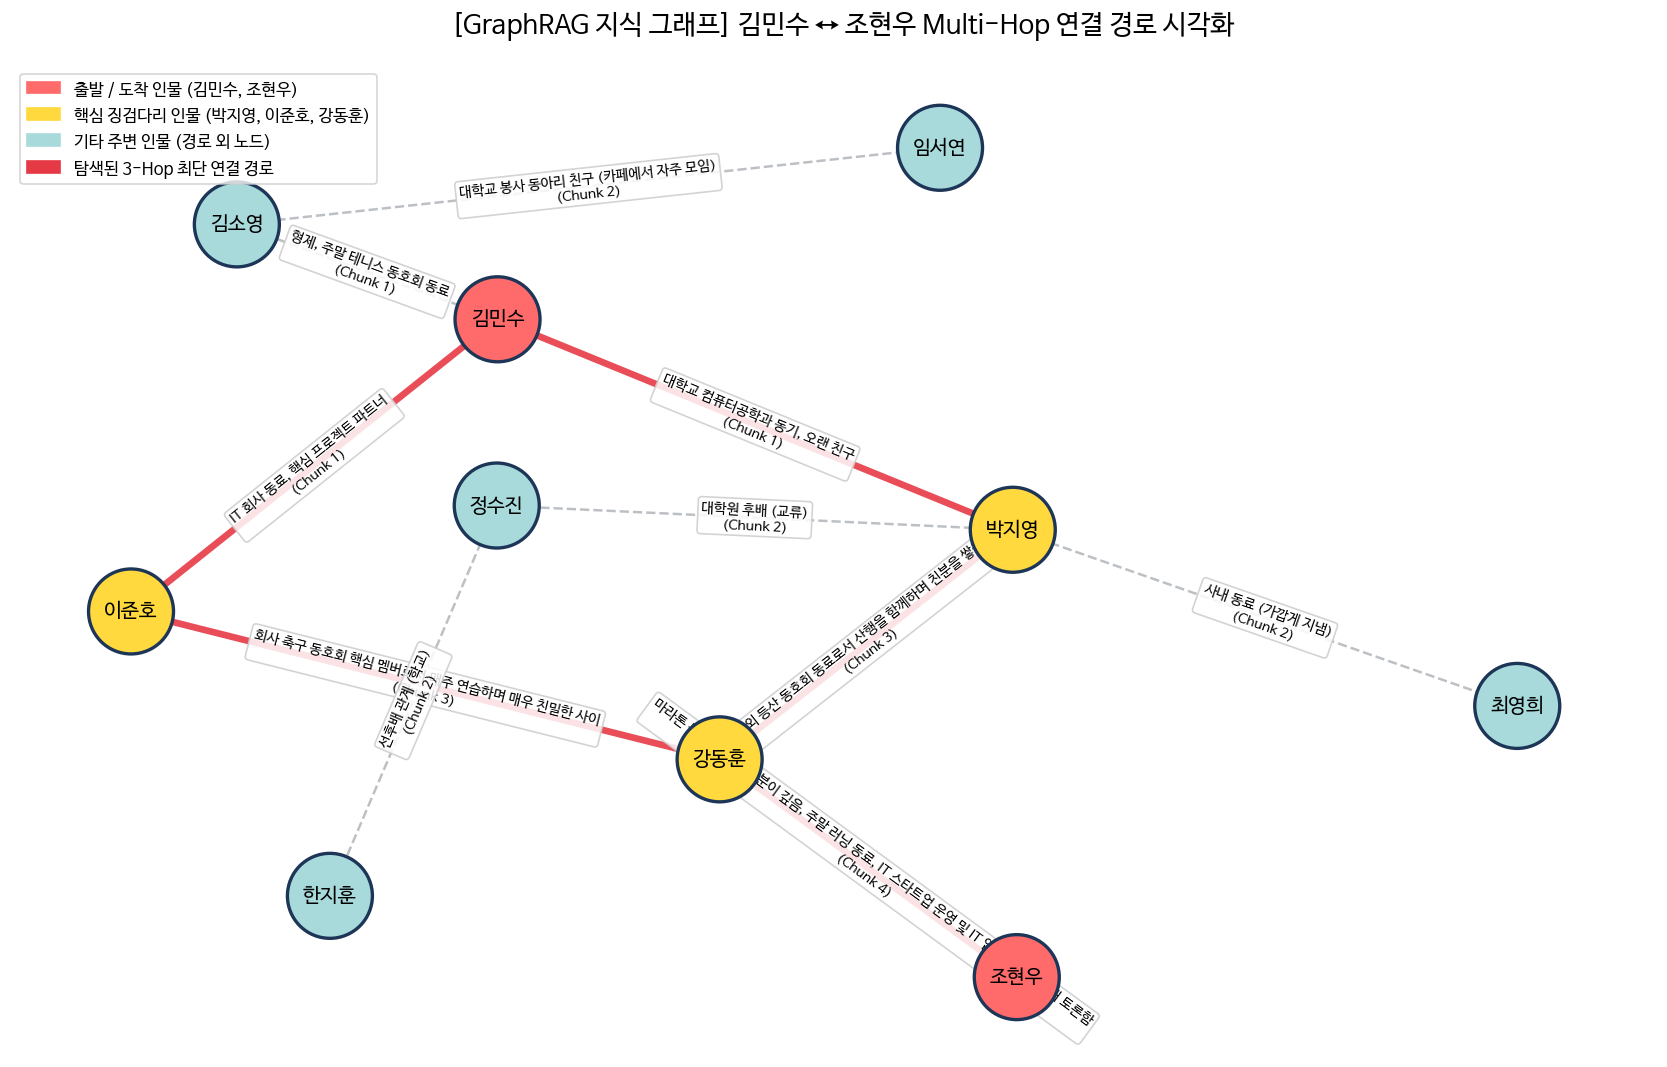

In [5]:
# =====================================================================
# [시각화 1] Matplotlib 기반 지식 그래프 및 최단 경로 하이라이트 시각화
# =====================================================================
start_person = "김민수"
end_person = "조현우"

# 두 인물 간의 모든 최단 경로(Shortest Paths) 계산 (BFS 기반)
shortest_paths = list(nx.all_shortest_paths(G, source=start_person, target=end_person))

# 최단 경로에 포함되는 노드 집합과 엣지 집합 추출
path_nodes = set(node for path in shortest_paths for node in path)
path_edges = set()
for path in shortest_paths:
    for i in range(len(path) - 1):
        # 무방향 그래프이므로 튜플을 정렬하여 저장
        path_edges.add(tuple(sorted((path[i], path[i+1]))))

# 그래프 레이아웃 설정 (k값으로 노드 간격 조정, seed 고정으로 재현성 확보)
plt.figure(figsize=(14, 9), dpi=120)
pos = nx.spring_layout(G, seed=42, k=1.3)

# 역할별 노드 색상 분류
node_colors = []
for node in G.nodes():
    if node in (start_person, end_person):
        node_colors.append("#FF6B6B")  # 출발/도착 노드 (코랄 레드)
    elif node in path_nodes:
        node_colors.append("#FFD93D")  # 징검다리 노드 (골드 옐로우)
    else:
        node_colors.append("#A8DADC")  # 주변부 일반 노드 (소프트 블루)

# 일반 엣지와 정답 경로 엣지 분리
normal_edges = [e for e in G.edges() if tuple(sorted(e)) not in path_edges]
highlight_edges = [e for e in G.edges() if tuple(sorted(e)) in path_edges]

# 1) 일반 엣지 그리기 (회색 점선)
nx.draw_networkx_edges(
    G, pos, edgelist=normal_edges,
    width=1.5, alpha=0.45, edge_color="#6C757D", style="dashed"
)

# 2) 정답 경로 엣지 그리기 (굵은 붉은색 실선)
nx.draw_networkx_edges(
    G, pos, edgelist=highlight_edges,
    width=4.0, alpha=0.9, edge_color="#E63946"
)

# 3) 노드 및 인물 이름 라벨 그리기
nx.draw_networkx_nodes(
    G, pos, node_color=node_colors,
    node_size=2600, edgecolors="#1D3557", linewidths=2.0
)
nx.draw_networkx_labels(
    G, pos, font_size=12, font_family="NanumBarunGothic", font_weight="bold"
)

# 4) 엣지 라벨 (관계 설명 + 출처 청크 번호) 표시
edge_labels = {
    (u, v): f"{data['relation']}\n(Chunk {data['chunk_id']})"
    for u, v, data in G.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels,
    font_size=8.5, font_family="NanumBarunGothic",
    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#CCCCCC", alpha=0.85)
)

# 범례(Legend) 수동 추가
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color="#FF6B6B", label="출발 / 도착 인물 (김민수, 조현우)"),
    mpatches.Patch(color="#FFD93D", label="핵심 징검다리 인물 (박지영, 이준호, 강동훈)"),
    mpatches.Patch(color="#A8DADC", label="기타 주변 인물 (경로 외 노드)"),
    mpatches.Patch(color="#E63946", label="탐색된 3-Hop 최단 연결 경로")
]
plt.legend(handles=legend_handles, loc="upper left", fontsize=10, frameon=True)

plt.title("🕸️ [GraphRAG 지식 그래프] 김민수 ↔ 조현우 Multi-Hop 연결 경로 시각화", fontsize=16, fontweight="bold", pad=20)
plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# =====================================================================
# [시각화 2] PyVis 기반 인터랙티브 그래프 시각화 (마우스 드래그 & 줌 지원)
# =====================================================================
from pyvis.network import Network
from IPython.display import HTML, display

# Colab 노트북 임베딩을 위한 PyVis 네트워크 객체 초기화
net = Network(height="550px", width="100%", bgcolor="#FFFFFF", font_color="#1D3557", notebook=True, cdn_resources="in_line")
net.barnes_hut(gravity=-3500, central_gravity=0.3, spring_length=180)

# 노드 추가 (역할에 따라 색상 및 크기 차등 부여)
for node in G.nodes():
    if node in (start_person, end_person):
        color = "#FF6B6B"
        size = 32
        group_desc = "타겟 인물 (출발/도착)"
    elif node in path_nodes:
        color = "#FFD93D"
        size = 26
        group_desc = "핵심 징검다리 인물"
    else:
        color = "#A8DADC"
        size = 20
        group_desc = "주변 지인"

    net.add_node(
        node,
        label=node,
        title=f"인물: {node} ({group_desc})",
        color=color,
        size=size,
        font={"size": 16, "face": "NanumBarunGothic"}
    )

# 엣지 추가 (최단 경로에 해당하는 엣지는 붉은색 굵은 선으로 강조)
for u, v, data in G.edges(data=True):
    is_shortest_path = tuple(sorted((u, v))) in path_edges
    net.add_edge(
        u, v,
        label=data["relation"],
        title=f"출처: Chunk {data['chunk_id']} | 관계: {data['relation']}",
        color="#E63946" if is_shortest_path else "#ADB5BD",
        width=4 if is_shortest_path else 1.5,
        font={"size": 11, "align": "top"}
    )

# HTML 파일로 저장 후 Colab 출력창에 렌더링
html_file = "graphrag_interactive_network.html"
net.write_html(html_file)
print("💡 아래 그래프에서 노드를 마우스로 클릭해 드래그하거나 스크롤로 확대/축소해 보세요!")
display(HTML(filename=html_file))

💡 아래 그래프에서 노드를 마우스로 클릭해 드래그하거나 스크롤로 확대/축소해 보세요!


## Step 6. GraphRAG 구현 (3): 멀티홉 경로 컨텍스트 추출 및 최종 답변 생성 (성공 시나리오)

그래프 탐색 알고리즘(`nx.all_shortest_paths`)이 찾아낸 **2가지 최단 경로**와 해당 엣지가 등장했던 **원본 문단(Chunk 1, 3, 4)**을 결합하여 로컬 LLM에 전달합니다.

* Standard Vector RAG가 놓쳤던 **Chunk 3 (`이준호/박지영 <-> 강동훈`)**이 그래프의 엣지 연결을 통해 자연스럽게 컨텍스트로 복원됩니다!

In [7]:
def build_graph_rag_context(graph: nx.Graph, docs_list: list, start_node: str, end_node: str) -> str:
    """
    지식 그래프에서 시작 노드와 도착 노드 사이의 모든 최단 경로를 탐색하고,
    경로 설명과 관련 원본 청크(Chunk) 텍스트를 결합한 풍부한 Context를 반환합니다.
    """
    if start_node not in graph or end_node not in graph:
        return "지식 그래프 내에 해당 인물이 존재하지 않습니다."

    # 1. 모든 최단 경로 탐색
    paths = list(nx.all_shortest_paths(graph, source=start_node, target=end_node))

    path_lines = []
    involved_chunk_ids = set()

    for idx, path in enumerate(paths, 1):
        hop_count = len(path) - 1
        steps_str = []
        for i in range(hop_count):
            u, v = path[i], path[i+1]
            edge_data = graph[u][v]
            rel = edge_data["relation"]
            cid = edge_data["chunk_id"]
            involved_chunk_ids.add(cid)
            steps_str.append(f"{u} ──({rel} [출처: 문단 {cid}])──> {v}")

        path_lines.append(f"• 경로 {idx} ({hop_count}-Hop): " + " ➡️ ".join(steps_str))

    # 2. 경로에 포함된 엣지들의 원본 문단(Chunk) 텍스트도 함께 수집 (Hybrid Graph + Text Context)
    chunk_map = {d.metadata["chunk_id"]: d.page_content for d in docs_list}
    supporting_chunks = [
        f"- [문단 {cid}] {chunk_map[cid]}"
        for cid in sorted(involved_chunk_ids)
    ]

    full_context = (
        "[1. 지식 그래프 최단 경로 탐색 결과]\n"
        + "\n".join(path_lines)
        + "\n\n[2. 경로 근거가 되는 원본 문단 텍스트]\n"
        + "\n".join(supporting_chunks)
    )
    return full_context

# GraphRAG 컨텍스트 생성 및 출력
graph_context = build_graph_rag_context(G, docs, "김민수", "조현우")

print("🧭 [GraphRAG가 추출한 멀티홉(Multi-Hop) 컨텍스트]")
print("=" * 70)
print(graph_context)
print("=" * 70)
print("👉 핵심 포인트: 벡터 검색에서 누락되었던 [문단 3]이 그래프 엣지 추적을 통해 완벽하게 포함되었습니다!\n")

# GraphRAG 답변 생성 프롬프트
graph_rag_prompt = ChatPromptTemplate.from_template("""
당신은 지식 그래프(Knowledge Graph)에서 탐색된 멀티홉 경로와 근거 문단을 바탕으로 명확하게 설명하는 AI 강사입니다.
주어진 [Context]를 바탕으로 질문에 대해 아래 형식으로 상세히 답변하세요.

1. 김민수에서 조현우로 이어지는 총 연결 경로의 개수와 요약
2. 각 경로별 단계적 연결 고리(동호회, 학교, 직장 등 구체적 맥락과 출처 문단 포함)

[Context]
{context}

[Question]
{question}

[Answer]
""")

graph_chain = graph_rag_prompt | llm | StrOutputParser()

print("🤖 [GraphRAG 최종 답변 생성 중...]")
try:
    graph_answer = graph_chain.invoke({
        "context": graph_context,
        "question": query
    })
    print("\n✅ [GraphRAG 답변 결과]:")
    print(graph_answer)
except Exception as e:
    print(f"\n⚠️ 로컬 LLM 서버 연결을 확인해주세요 ({LOCAL_BASE_URL}): {e}")

🧭 [GraphRAG가 추출한 멀티홉(Multi-Hop) 컨텍스트]
[1. 지식 그래프 최단 경로 탐색 결과]
• 경로 1 (3-Hop): 김민수 ──(대학교 컴퓨터공학과 동기, 오랜 친구 [출처: 문단 1])──> 박지영 ➡️ 박지영 ──(사외 등산 동호회 동료로서 산행을 함께하며 친분을 쌓음 [출처: 문단 3])──> 강동훈 ➡️ 강동훈 ──(마라톤 동호회 회원, 친분이 깊음, 주말 러닝 동료, IT 스타트업 운영 및 IT 업계 동향에 대해 토론함 [출처: 문단 4])──> 조현우
• 경로 2 (3-Hop): 김민수 ──(IT 회사 동료, 핵심 프로젝트 파트너 [출처: 문단 1])──> 이준호 ➡️ 이준호 ──(회사 축구 동호회 핵심 멤버로서 매주 연습하며 매우 친밀한 사이 [출처: 문단 3])──> 강동훈 ➡️ 강동훈 ──(마라톤 동호회 회원, 친분이 깊음, 주말 러닝 동료, IT 스타트업 운영 및 IT 업계 동향에 대해 토론함 [출처: 문단 4])──> 조현우

[2. 경로 근거가 되는 원본 문단 텍스트]
- [문단 1] 김민수는 대학교 컴퓨터공학과 동기인 박지영과 오랜 친구 관계를 유지하고 있습니다. 현재 IT 회사에 재직 중인 김민수는 같은 회사 동료인 이준호와 함께 핵심 프로젝트를 진행하며 긴밀한 업무 파트너십을 맺고 있습니다. 가족 관계로는 김소영이 형제이며, 주말마다 함께 테니스 동호회에 나가 테니스를 즐깁니다.
- [문단 3] 사내외 동호회 활동을 통한 교류도 무척 활발합니다. 회사 내 축구 동호회에서 핵심 멤버로 뛰고 있는 이준호는 부서가 다른 강동훈과 매주 연습을 하며 매우 막역한 사이가 되었습니다. 박지영 역시 사외 등산 동호회에서 강동훈을 알게 되어 종종 산행을 함께 하며 친분을 쌓았습니다.
- [문단 4] 최근 IT 스타트업을 창업한 조현우는 업무 스트레스를 풀기 위해 마라톤 동호회에 가입했습니다. 조현우는 이 마라톤 동호회에서 강동훈을 만나 깊은 친분을 맺었으며, 주말마다 함께 러닝을 하며 스타트업 운영 및 IT 업계 동향에 대한 

## 📊 강좌 마무리 요약: Standard Vector RAG vs. GraphRAG

| 비교 항목 | Standard Vector RAG (`FAISS`, `Top-K=2`) | GraphRAG (`NetworkX` + `Structured Output`) |
| :--- | :--- | :--- |
| **검색 단위** | 분할된 텍스트 청크 (Text Chunk) | 엔티티(Node), 관계(Edge), 서브그래프 경로 |
| **검색 알고리즘** | 임베딩 벡터 간 코사인 유사도 (Cosine Similarity) | 그래프 탐색 알고리즘 (BFS 최단 경로 탐색) |
| **징검다리 문단(Chunk 3) 포착** | ❌ **실패** ('김민수', '조현우' 키워드 부재로 유사도 하위권) | ✅ **성공** (`박지영/이준호` $\leftrightarrow$ `강동훈` 엣지로 연결) |
| **최종 추론 결과** | 두 사람의 연결 고리를 찾을 수 없다고 응답 | **박지영-강동훈**, **이준호-강동훈**을 경유하는 2가지 3-Hop 경로 완벽 도출 |